# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_1458.csv',
        ),
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')

In [6]:
data.to_csv('results/SATReset_1458.csv', index = False)

In [7]:
data['result'] = data['info'].str.split(';').str[0].where(data.solved, 'Unsolved')

In [8]:
data.head()

,problem,strategy,status,solved,steps,time_ms,info,error,result
0,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
1,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
2,AGT002+2.p,SATResetAtStaleAction,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleAct...,NaN,Theorem (SAT)
3,AGT002+2.p,SATResetAtStaleBacktrack,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleBac...,NaN,Theorem (SAT)
4,AGT002+2.p,SATResetBandit,solved,True,0.0,0.0,"Theorem (SAT); reset=policy:SATResetBandit,cut...",NaN,Theorem (SAT)


In [9]:
pandas.crosstab(
    data.strategy,
    data.result,
)

result,Theorem,Theorem (SAT),Unsolved
strategy,,,
FirstAction,70,0,1290
LeanCopCut,178,0,1182
SATResetAtStaleAction,0,276,1084
SATResetAtStaleBacktrack,0,277,1083
SATResetAtStaleBacktrackTableau,69,194,1097
SATResetAtTwo,0,279,1081
SATResetAtTwoTableau,69,198,1093
SATResetBandit,0,255,1105
SATResetStart,0,272,1088


In [23]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,55,ALG,385.0,ANA,88.0
1,BIO,11,BOO,132.0,CAT,143.0
2,COL,242,COM,99.0,CSR,517.0
3,FLD,176,GEO,737.0,GRA,44.0
4,GRP,1122,HAL,33.0,HEN,55.0
5,HWC,11,HWV,429.0,KLE,253.0
6,KRS,319,LAT,660.0,LCL,759.0
7,LDA,55,MED,22.0,MGT,154.0
8,MSC,22,NLP,638.0,NUM,902.0
9,NUN,11,PHI,11.0,PLA,88.0


# Analysing

In [11]:
control = ['FirstAction', 'LeanCopCut']

In [12]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error,result
0,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
1,AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN,Theorem (SAT)
2,AGT002+2.p,SATResetAtStaleAction,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleAct...,NaN,Theorem (SAT)
3,AGT002+2.p,SATResetAtStaleBacktrack,solved,True,0.0,0.0,Theorem (SAT); reset=policy:SATResetAtStaleBac...,NaN,Theorem (SAT)
4,AGT002+2.p,SATResetBandit,solved,True,0.0,0.0,"Theorem (SAT); reset=policy:SATResetBandit,cut...",NaN,Theorem (SAT)
...,...,...,...,...,...,...,...,...,...
14917,SYN948+1.p,SATResetAtTwoTableau,solved,True,2.0,0.0,"Theorem; literal=choices:2,forward:4,unique:1,...",NaN,Theorem
14918,SYN969+1.p,SATResetAtStaleBacktrackTableau,solved,True,7.0,1.0,"Theorem; literal=choices:6,forward:12,unique:4...",NaN,Theorem
14919,SYN969+1.p,SATResetAtTwoTableau,solved,True,10.0,1.0,"Theorem; literal=choices:8,forward:17,unique:5...",NaN,Theorem
14920,SYN971+1.p,SATResetAtStaleBacktrackTableau,solved,True,2.0,0.0,"Theorem; literal=choices:2,forward:3,unique:1,...",NaN,Theorem


In [13]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                         70
LeanCopCut                         178
SATResetAtStaleAction              276
SATResetAtStaleBacktrack           277
SATResetAtStaleBacktrackTableau    263
SATResetAtTwo                      279
SATResetAtTwoTableau               267
SATResetBandit                     255
SATResetStart                      272
SATSolve                           159
SATSolveLiteral                    243
dtype: int64

In [26]:
pandas.crosstab(data.strategy, data.result).sort_values('Unsolved', ascending = False)

result,Theorem,Theorem (SAT),Unsolved
strategy,,,
FirstAction,70,0,1290
SATSolve,0,159,1201
LeanCopCut,178,0,1182
SATSolveLiteral,0,243,1117
SATResetBandit,0,255,1105
SATResetAtStaleBacktrackTableau,69,194,1097
SATResetAtTwoTableau,69,198,1093
SATResetStart,0,272,1088
SATResetAtStaleAction,0,276,1084


# Results

<Axes: xlabel='strategy'>

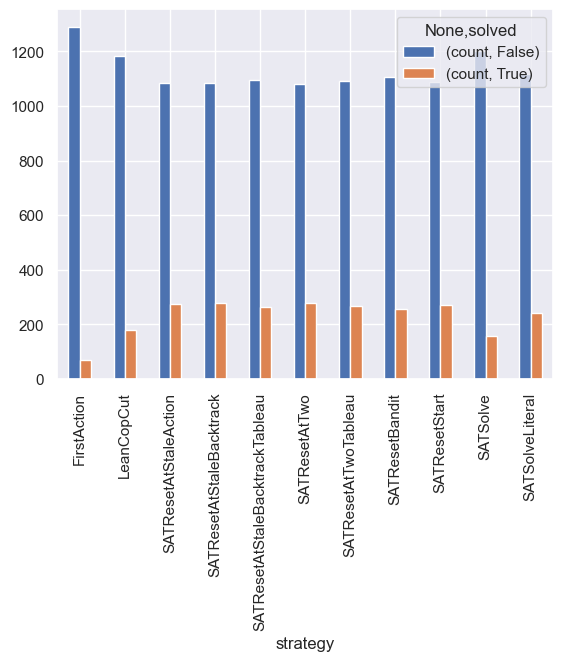

In [14]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

In [15]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [16]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetAtStaleBacktrackTableau,SATResetAtTwo,SATResetAtTwoTableau,SATResetBandit,SATResetStart,SATSolve,SATSolveLiteral
strategy_left,,,,,,,,,,,
FirstAction,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
LeanCopCut,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleAction,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleBacktrack,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtStaleBacktrackTableau,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtTwo,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetAtTwoTableau,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetBandit,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360
SATResetStart,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360,1360


<Axes: xlabel='Winner', ylabel='Loser'>

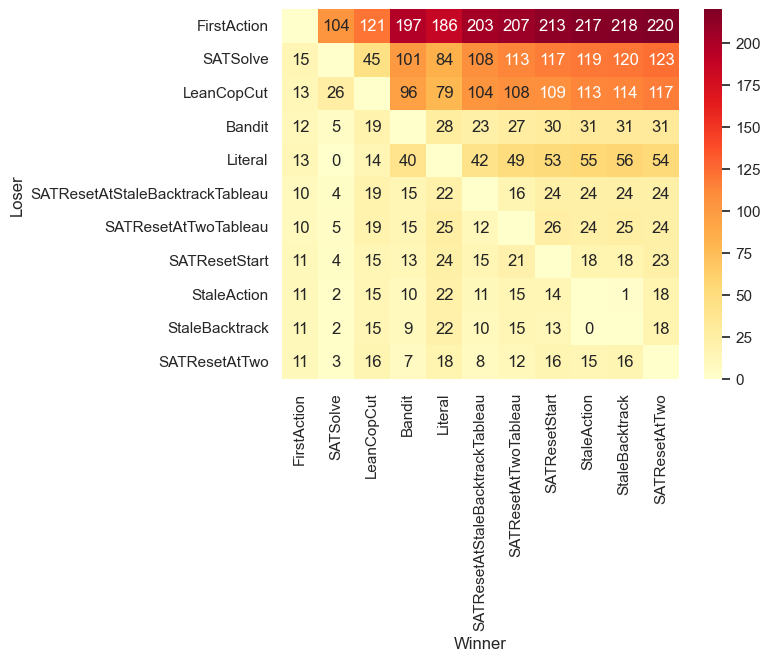

In [17]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATSolve',
    'SATSolveLiteral': 'Literal',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

# Analysis

In [18]:
merged[~merged.solved_left & merged.solved_right].loc[lambda x: (x.strategy_left == 'SATResetAtStaleAction') & (x.strategy_right == 'SATResetAtStaleBacktrack')]

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,result_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right,result_right
38250,NUM508+3.p,SATResetAtStaleAction,timeout,False,5158.0,120010.0,"score=1.0; literal=choices:4460,forward:592870...",NaN,Unsolved,SATResetAtStaleBacktrack,solved,True,5345.0,111125.0,Theorem (SAT); score=1.0; literal=choices:4626...,NaN,Theorem (SAT)


In [19]:
data.groupby('strategy').result.value_counts()

strategy                         result       
FirstAction                      Unsolved         1290
                                 Theorem            70
LeanCopCut                       Unsolved         1182
                                 Theorem           178
SATResetAtStaleAction            Unsolved         1084
                                 Theorem (SAT)     276
SATResetAtStaleBacktrack         Unsolved         1083
                                 Theorem (SAT)     277
SATResetAtStaleBacktrackTableau  Unsolved         1097
                                 Theorem (SAT)     194
                                 Theorem            69
SATResetAtTwo                    Unsolved         1081
                                 Theorem (SAT)     279
SATResetAtTwoTableau             Unsolved         1093
                                 Theorem (SAT)     198
                                 Theorem            69
SATResetBandit                   Unsolved         1105
                  

In [20]:
data[(data.strategy == 'LeanCopCut') & (data['info'].str.startswith('Theorem (SAT)'))]

,problem,strategy,status,solved,steps,time_ms,info,error,result
